## LESSON 1: ENSEMBLE LEARNING

In [3]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.tree import DecisionTreeClassifier
datas={
    "possession":[60, 45, 55, 70, 25, 40,35],
    "shots":[15, 7, 12, 13, 6, 17, 22],
    "shots_on_target":[8, 2, 6, 1, 5, 10, 9],
    "pass_accuracy":[75, 32, 82, 34, 25, 57, 49],
    "win":[1, 0, 1, 0, 0, 1, 1]
}
df=pd.DataFrame(datas)
X=df.drop("win", axis=1)
y=df["win"]
print(X.head())

X_train, X_test, y_train, y_test=train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

models={
    "logistic_regression: ": LogisticRegression(max_iter=1000),
    "decision_tree_classifier: ":DecisionTreeClassifier(random_state=42),
    "random_forest_classifier :":RandomForestClassifier(n_estimators=100, random_state=42)
}
for name, model in models.items():
    model.fit(X_train, y_train)
    score=model.score(X_test, y_test)
    print(name, score)

ensemble=VotingClassifier(
    estimators=[
        ("dt", DecisionTreeClassifier(random_state=42)),
        ("rf", RandomForestClassifier(n_estimators=100, random_state=42)),
        ("lr", LogisticRegression(max_iter=1000))
    ],
    voting="hard"
)
ensemble.fit(X_train, y_train)
y_pred=ensemble.predict(X_test)
print("Ensemble Accuracy: ", ensemble.score(X_test, y_test))
print("Prediction", y_pred)

   possession  shots  shots_on_target  pass_accuracy
0          60     15                8             75
1          45      7                2             32
2          55     12                6             82
3          70     13                1             34
4          25      6                5             25
logistic_regression:  1.0
decision_tree_classifier:  0.5
random_forest_classifier : 1.0
Ensemble Accuracy:  1.0
Prediction [1 0]


# NOTE:
---
~~~ 
Ensemble Learning combines multiple models.
Bagging trains models independently using different samples.
Boosting trains models sequentially to improve predictions.
Stacking combines model predictions using another model.
Random Forest is an example of Bagging.
XGBoost and LightGBM are example of Boosting.
Voting combines predictions using majority voting or probability averaging.
~~~
---

## LESSON 2: Bagging Vs Boosting

In [4]:
import pandas as pd
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split

X, y=make_classification(
    n_samples=100,
    n_features=8,
    n_informative=5,
    n_redundant=1,
    class_sep=0.8,
    flip_y=0.05,
    random_state=42
)
feature_names=[
    "possession",
    "shots",
    "shots_on_target",
    "pass_accuracy",
    "corners",
    "tackles",
    "fouls",
    "distance_covered"
]
X=pd.DataFrame(X, columns=feature_names)
y=pd.Series(y, name="win")

X_train, X_test, y_train, y_test=train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Bagging implementation
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier
bagging_model=BaggingClassifier(
    estimator=DecisionTreeClassifier(),
    n_estimators=100,
    max_samples=0.8,
    bootstrap=True,
    random_state=42,
    n_jobs=-1
)
bagging_model.fit(X_train, y_train)
bagging_pred= bagging_model.predict(X_test)

# Boosting model
from sklearn.ensemble import AdaBoostClassifier
boosting_model=AdaBoostClassifier(
    estimator=DecisionTreeClassifier(),
    learning_rate=0.5,
    n_estimators=100,
    random_state=42
)
boosting_model.fit(X_train, y_train)
boosting_pred= boosting_model.predict(X_test)

# Comparision
from sklearn.metrics import accuracy_score, f1_score
results=pd.DataFrame({
    "Model":["Bagging", "Boosting(ADABoost)"],
    "Accuracy":[
        accuracy_score(y_test, bagging_pred),
        accuracy_score(y_test, boosting_pred)
    ],
    "F1_score":[
        f1_score(y_test, bagging_pred),
        f1_score(y_test, boosting_pred)
    ]
})

print(results)

                Model  Accuracy  F1_score
0             Bagging      0.85  0.823529
1  Boosting(ADABoost)      0.80  0.777778


# NOTE:
---
~~~ 
Bagging: Independent model training.
Bootstrap: Sampling with replacement.
Variance: Sensitivity to traning data.
Boosting: Sequential model improvement.
AdaBoost: Focuses on misclassified samples.
GradientBoosting: Learns Corrections using Gradients.
RandomForest: Bagging-based ensemble.
XGBoost: Advanced/Optimized Gradient Boosting
LightGBM: Efficient Gradient Boosting Framework.
~~~
---

## LESSON 3: GRADIENT BOOSTING

In [5]:
import pandas as pd
from sklearn.datasets import make_classification
X, y=make_classification(
    n_samples=100,
    n_features=8,
    n_informative=5,
    n_redundant=1,
    class_sep=0.8,
    flip_y=0.05,
    random_state=42
)
feature_names=[
    "possession",
    "shots",
    "shots_on_target",
    "pass_accuracy",
    "corners",
    "tackles",
    "fouls",
    "distance_covered"
]
X=pd.DataFrame(X, columns=feature_names)
y=pd.Series(y, name="win")

# Train/Test Split
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test=train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
# Training Gradient Boosting
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score

params={
    "n_estimators":[50, 100, 200],
    "learning_rate":[0.01, 0.1, 0.5]
}
g_results=[]
for n in params["n_estimators"]:
    for l in params["learning_rate"]:
        g_model=GradientBoostingClassifier(
            n_estimators=n,
            learning_rate=l,
            random_state=42,
            max_depth=3
        )
        g_model.fit(X_train, y_train)
        g_pred=g_model.predict(X_test)
        print(g_pred)
        g_results.append({
            "Estimator":n,
            "learning Rate": l,
            "Accuracy": accuracy_score(y_test, g_pred),
            "F1 Score": f1_score(y_test, g_pred)
        })
g_results_df=pd.DataFrame(g_results)
print(g_results_df)

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import AdaBoostClassifier
models={
    "DECISION TREE":DecisionTreeClassifier(random_state=42),
    "RANDOM FOREST":RandomForestClassifier(n_estimators=100, random_state=42),
    "ADABOOST":AdaBoostClassifier(n_estimators=100, random_state=42),
    "GRADIENT BOOSTING":GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42)
}
results=[]
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred=model.predict(X_test)
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "F1_score": f1_score(y_test, y_pred)
    })
results_df=pd.DataFrame(results)
print(results_df.sort_values(by="Accuracy", ascending=False))

[1 0 1 1 1 0 0 0 0 0 1 1 0 0 0 0 1 0 1 1]
[1 0 1 1 1 0 0 0 0 0 0 1 0 0 0 0 1 0 1 1]
[1 0 1 1 1 0 0 0 0 0 0 1 0 0 0 0 1 0 1 1]
[1 0 1 1 0 0 0 0 0 0 1 1 0 0 0 1 1 0 1 1]
[1 0 1 1 1 0 0 0 0 0 0 1 0 0 0 1 1 0 1 1]
[1 0 1 0 1 0 0 0 0 0 0 1 0 0 0 0 0 0 1 1]
[1 0 1 1 1 0 0 0 0 0 0 1 0 0 0 0 1 0 1 1]
[1 0 1 0 1 0 0 0 0 0 0 1 0 0 0 1 0 0 1 1]
[1 0 1 0 1 0 0 0 0 0 0 1 0 0 0 0 0 0 1 1]
   Estimator  learning Rate  Accuracy  F1 Score
0         50           0.01      0.75  0.736842
1         50           0.10      0.80  0.777778
2         50           0.50      0.80  0.777778
3        100           0.01      0.85  0.842105
4        100           0.10      0.85  0.842105
5        100           0.50      0.70  0.625000
6        200           0.01      0.80  0.777778
7        200           0.10      0.75  0.705882
8        200           0.50      0.70  0.625000
               Model  Accuracy  F1_score
1      RANDOM FOREST      0.85  0.842105
3  GRADIENT BOOSTING      0.85  0.842105
2           ADABOOS

# NOTE:
---
~~~ 
Gradient Boosting is an ensemble learning technique.
Models are trained sequentially.
Each new model helps reduce the remining errors.
Decision Trees are commonly used as weak learners.
Residual= Actaul Value - Predicted Value (for squared error regression).
Learning rate controls the contribution of each tree.
More tree do not autoatically mean better performance.
XGBoost is an advanced implementation of Gradient Boosting.
~~~
---

## LESSON 4: EXTREME GRADIENT BOOSTING (XGBoosting)

In [6]:
import pandas as pd
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report
X, y=make_classification(
    n_samples=100,
    n_features=8,
    n_informative=5,
    n_redundant=1,
    class_sep=0.8,
    flip_y=0.05,
    random_state=42
)
feature_names=[
    "possession",
    "shots",
    "shots_on_target",
    "pass_accuracy",
    "corners",
    "tackles",
    "fouls",
    "distance_covered"
]
X=pd.DataFrame(X, columns=feature_names)
y=pd.Series(y, name="win")

X_train, X_test, y_train, t_test= train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42, stratify=y
)

xgb_model= XGBClassifier(
    n_estimators=200,
    learning_rate=0.05,
    subsample=0.8,
    max_depth=4,
    reg_alpha=0.1,
    reg_lambda=1,
    random_state=42
)
xgb_model.fit(X_train, y_train)
xgb_pred= xgb_model.predict(X_test)
print(xgb_pred)
print("accuracy_score: ",accuracy_score(y_test, xgb_pred))
print("precsion_score: ",precision_score(y_test, xgb_pred))
print(" recall_score: ",recall_score(y_test, xgb_pred))
print(" f1_score: ",f1_score(y_test, xgb_pred))
print("Classification Report: ",classification_report(y_test, xgb_pred))

models={
    "DECISION TREE":DecisionTreeClassifier(random_state=42),
    "RANDOM FOREST":RandomForestClassifier(n_estimators=100, random_state=42),
    "XGBOOST":XGBClassifier(n_estimators=200, learning_rate=0.05, max_depth=4, random_state=42),
    "GRADIENT BOOSTING":GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42)
}
results=[]
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred=model.predict(X_test)
    results.append({
        "Models": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1 Score": f1_score(y_test, y_pred)
    })
results_df= pd.DataFrame(results)
print(results_df.sort_values(by="F1 Score", ascending=False))

[1 0 1 1 1 0 0 0 0 0 0 1 0 0 0 1 1 0 1 1]
accuracy_score:  0.85
precsion_score:  0.8888888888888888
 recall_score:  0.8
 f1_score:  0.8421052631578947
Classification Report:                precision    recall  f1-score   support

           0       0.82      0.90      0.86        10
           1       0.89      0.80      0.84        10

    accuracy                           0.85        20
   macro avg       0.85      0.85      0.85        20
weighted avg       0.85      0.85      0.85        20

              Models  Accuracy  Precision  Recall  F1 Score
1      RANDOM FOREST      0.85   0.888889     0.8  0.842105
2            XGBOOST      0.85   0.888889     0.8  0.842105
3  GRADIENT BOOSTING      0.85   0.888889     0.8  0.842105
0      DECISION TREE      0.75   0.777778     0.7  0.736842


## LESSON 5: LIGHTGBM (LIGHT GRADIENT BOOSTING MACHINE )

In [7]:
import pandas as pd
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from lightgbm import LGBMClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
X, y=make_classification(
    n_samples=100,
    n_features=10,
    n_informative=5,
    n_redundant=2,
    random_state=42
)
feature_names=[
    "possession",
    "shots",
    "shots_on_target",
    "pass_accuracy",
    "corners",
    "tackles",
    "fouls",
    "opponent_strength",
    "form",
    "distance_covered"
]
X=pd.DataFrame(X, columns=feature_names)
y=pd.Series(y, name="win")

X_train, X_test, y_train, y_test= train_test_split(
X,
y,
stratify=y,
test_size=0.2,
random_state=42
)
lightGBM_result=[]
for e in [100, 200, 300]:
    for lr in [0.1, 0.05, 0.01]:
        for l in [15, 20, 31]:
            light_model=LGBMClassifier(
                n_estimators=e,
                learning_rate=lr,
                num_leaves=l,
                reg_alpha=0.1,
                reg_lambda=1,
                random_state=42
            )
            light_model.fit(X_train, y_train)
            light_pred= light_model.predict(X_test)
            lightGBM_result.append({
                "Estimators": e,
                "Learning Rate": lr,
                "Number of leaves": l,
                "Accuracy": accuracy_score(y_test, light_pred),
                "Precision": precision_score(y_test, light_pred),
                "Recall": recall_score(y_test, light_pred),
                "F1 Score": f1_score(y_test, light_pred)
            })
lightGBM_result_df=pd.DataFrame(lightGBM_result)
print(lightGBM_result_df)

models={
    "LIGHT GBM":LGBMClassifier(n_estimators=100, learning_rate=0.05, num_leaves=15,reg_alpha=0.1, reg_lambda=1, random_state=42),
    "RANDOM FOREST":RandomForestClassifier(n_estimators=100, random_state=42),
    "XGBOOST":XGBClassifier(n_estimators=200, learning_rate=0.05, max_depth=4, random_state=42),
    "GRADIENT BOOSTING":GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42)
}
l_results=[]
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred= model.predict(X_test)
    l_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1 Score": f1_score(y_test, y_pred)
    })
l_results_df= pd.DataFrame(l_results)
print(l_results_df.sort_values(by="F1 Score", ascending=False))

    Estimators  Learning Rate  Number of leaves  ...  Precision  Recall  F1 Score
0          100           0.10                15  ...   0.750000     0.9  0.818182
1          100           0.10                20  ...   0.750000     0.9  0.818182
2          100           0.10                31  ...   0.750000     0.9  0.818182
3          100           0.05                15  ...   0.750000     0.9  0.818182
4          100           0.05                20  ...   0.750000     0.9  0.818182
5          100           0.05                31  ...   0.750000     0.9  0.818182
6          100           0.01                15  ...   0.888889     0.8  0.842105
7          100           0.01                20  ...   0.888889     0.8  0.842105
8          100           0.01                31  ...   0.888889     0.8  0.842105
9          200           0.10                15  ...   0.750000     0.9  0.818182
10         200           0.10                20  ...   0.750000     0.9  0.818182
11         200  

# NOTE:
---
~~~ 
LightGBM developed by Microsoft.
Uses Gradient Boosting, leaf-wise tree growth, histogram_based learning.
num_leaves controls tree complexity.
Leaf-wise growth can cause overfitting in small datasets.
Always compare XGBoost and LightGBM experimentally.
~~~
---

## LESSON 6: Hyperparameter Tuning

In [8]:
import pandas as pd
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from xgboost import XGBClassifier
from scipy.stats import randint, uniform
from sklearn.metrics import f1_score

X,y= make_classification(
    n_samples=3000,
    n_features=10,
    n_informative=6,
    n_redundant=2,
    random_state=42
)
X_train, X_test, y_train, y_test= train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
model=XGBClassifier(
    eval_metric="logloss",
    random_state=42
)
param_grids={
    "n_estimators":[100, 200],
    "max_depth":[3,5],
    "learning_rate":[0.01, 0.1]
}
grid_search=GridSearchCV(
    estimator=model,
    param_grid=param_grids,
    scoring="f1",
    cv=5,
    n_jobs=-1,
    verbose=1
)
grid_search.fit(X_train, y_train)
print("Best Parameter: ", grid_search.best_params_)
print("Best CV Score: ", grid_search.best_score_)

param_dist={
    "n_estimators":randint(100, 501),
    "max_depth":randint(2,9),
    "learning_rate":uniform(0.01, 0.19),
    "subsample":uniform(0.6, 0.4),
    "colsample_bytree":uniform(0.6, 0.4)
}
random_search= RandomizedSearchCV(
    estimator=model,
    param_distributions=param_dist,
    n_iter=20,
    scoring="f1",
    cv=5,
    random_state=42,
    n_jobs=-1,
    verbose=1
)
random_search.fit(X_train, y_train)
print("Best Parameters: ", random_search.best_params_)
print("Best CV Score: ", random_search.best_score_)
print("F1 Score by GRID", f1_score(y_test,grid_search.predict(X_test)))
print("F1 Score by Randomized", f1_score(y_test, random_search.predict(X_test)))

Fitting 5 folds for each of 8 candidates, totalling 40 fits
Best Parameter:  {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 200}
Best CV Score:  0.9322030358118087
Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best Parameters:  {'colsample_bytree': np.float64(0.9140703845572055), 'learning_rate': np.float64(0.047938018610088354), 'max_depth': 8, 'n_estimators': 343, 'subsample': np.float64(0.836965827544817)}
Best CV Score:  0.9379098494026081
F1 Score by GRID 0.9435215946843853
F1 Score by Randomized 0.956953642384106


# NOTE:
---
~~~ 
Hyperparameter tuning finds suitable model settings.
Model parameters are learned during training.
Hyperparameters are chosen before or during training.
GridSearch tests all specified combinations
RandomizedSearch tests randomly selected combinations.
Cross-Validation provides a more reliable performance estimate.
Bayesian Optimization uses previous experiments to guide future searches.
Never tune using your final test dataset.
~~~
---

## LESSON 7: EARLY STOPPING

In [5]:
import pandas as pd
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier, early_stopping
from sklearn.metrics import accuracy_score, f1_score
X,y= make_classification(
    n_samples=3000,
    n_features=10,
    n_informative=6,
    n_redundant=2,
    random_state=42
)
X_train, X_test, y_train, y_test= train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
XGB_model =XGBClassifier(n_estimators=1000, early_stopping_rounds=30,  learning_rate=0.05, max_depth=4, random_state=42)
LGBM_model =LGBMClassifier(n_estimators=1000, learning_rate=0.05, num_leaves=20, random_state=42, verbosity=-1)
XGB_model.fit(X_train, y_train, eval_set=[(X_test, y_test)])
LGBM_model.fit(X_train, y_train, eval_set=[(X_test, y_test)], callbacks=[
    early_stopping(
        stopping_rounds=30,
        verbose=False
    )
])
x_pred=XGB_model.predict(X_test)
l_pred=LGBM_model.predict(X_test)
print("ACCURACY SCORE by XGBoost: ", accuracy_score(y_test, x_pred))
print("ACCURACY SCORE by LightGBM: ", accuracy_score(y_test, l_pred))
print("F1 SCORE by XGBoost: ", accuracy_score(y_test, x_pred))
print("F1 SCORE by LightGBM: ", accuracy_score(y_test, l_pred))


[0]	validation_0-logloss:0.66233
[1]	validation_0-logloss:0.63446
[2]	validation_0-logloss:0.60874
[3]	validation_0-logloss:0.58567
[4]	validation_0-logloss:0.56423
[5]	validation_0-logloss:0.54426
[6]	validation_0-logloss:0.52544
[7]	validation_0-logloss:0.50842
[8]	validation_0-logloss:0.49247
[9]	validation_0-logloss:0.47778
[10]	validation_0-logloss:0.46440
[11]	validation_0-logloss:0.45127
[12]	validation_0-logloss:0.43939
[13]	validation_0-logloss:0.42649
[14]	validation_0-logloss:0.41481
[15]	validation_0-logloss:0.40454
[16]	validation_0-logloss:0.39399
[17]	validation_0-logloss:0.38408
[18]	validation_0-logloss:0.37649
[19]	validation_0-logloss:0.36814
[20]	validation_0-logloss:0.35990
[21]	validation_0-logloss:0.35257
[22]	validation_0-logloss:0.34630
[23]	validation_0-logloss:0.33949
[24]	validation_0-logloss:0.33363
[25]	validation_0-logloss:0.32811
[26]	validation_0-logloss:0.32238
[27]	validation_0-logloss:0.31663
[28]	validation_0-logloss:0.31166
[29]	validation_0-loglos

c:\Users\anamo\OneDrive\Desktop\pythonDownload\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


ACCURACY SCORE by XGBoost:  0.9416666666666667
ACCURACY SCORE by LightGBM:  0.9516666666666667
F1 SCORE by XGBoost:  0.9416666666666667
F1 SCORE by LightGBM:  0.9516666666666667


# NOTE:
---
~~~ 
Early Stopping stops training when validation performance stops improving.
n_estimators defines the maximum number of boosting rounds.
Patience defines how long to wait for improvement.
best_iteration defines the best boosting round.
Validation data monitors training performance.
Test data is reserved for final evaluation.
Early stopping can reduce unnecessary training and help control overfitting.
~~~
---

## LESSON 8: HANDLE IMBALANCE DATASET

In [7]:
from sklearn.datasets import make_classification
from collections import Counter
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split
X,y = make_classification(
    n_samples=1000,
    n_features=10,
    weights=[0.9, 0.1],
    random_state=42
)
print(Counter(y))
X_train, X_test, y_train, y_test= train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
# Applying Random Sampling
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler

ros=RandomOverSampler(random_state=42)
X_resampled, y_resampled=ros.fit_resample(X,y)
print(Counter(y_resampled))

rus= RandomUnderSampler(random_state=42)
X_under, y_under= rus.fit_resample(X, y)
print(Counter(y_under))

smote=SMOTE(random_state=42)
X_smote, y_smote=smote.fit_resample(X,y)
print(Counter(y_smote))

# Class weight
# For Random FOrest
from sklearn.ensemble import RandomForestClassifier
model=RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=42)
model.fit(X_train, y_train)
print(confusion_matrix(y_test, model.predict(X_test)))

#For XGBoost
from xgboost import XGBClassifier
xgb_model=XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=5, scale_pos_weight=8.6, eval_metrics="logloss", random_state=42)
xgb_model.fit(X_train, y_train) 
print(confusion_matrix(y_test, xgb_model.predict(X_test)))


Counter({np.int64(0): 897, np.int64(1): 103})
Counter({np.int64(0): 897, np.int64(1): 897})
Counter({np.int64(0): 103, np.int64(1): 103})
Counter({np.int64(0): 897, np.int64(1): 897})
[[176   3]
 [  8  13]]
[[175   4]
 [  6  15]]


# NOTE:
---
~~~ 
Imbalanced data has unequal class distribution.
Oversampling  increases minority examples.
Understanding reduces majority examples.
SMOTE creates synthetic minority examples.
Class weights increases the importance of minority class errors.
Accuracy alone can be misleading.
Never resample the test dataset.
~~~
---

## MODEL COMPARISION

                 Model  Accuracy  Precision  ...   ROC-AUC    PR-AUC  Training time
0  Logistic Regression  0.906667   0.888179  ...  0.906743  0.860798       0.111576

[1 rows x 8 columns]


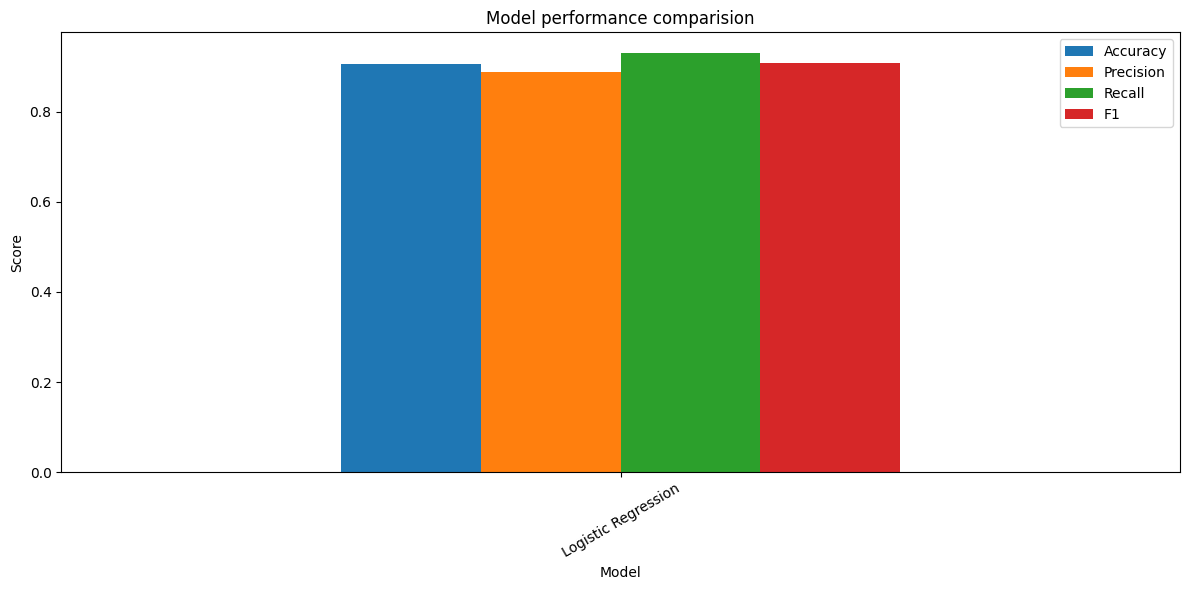

                 Model  Accuracy  Precision  ...   ROC-AUC    PR-AUC  Training time
0  Logistic Regression  0.906667   0.888179  ...  0.906743  0.860798       0.111576
1             Decision  0.891667   0.903448  ...  0.891615  0.853317       0.034375

[2 rows x 8 columns]


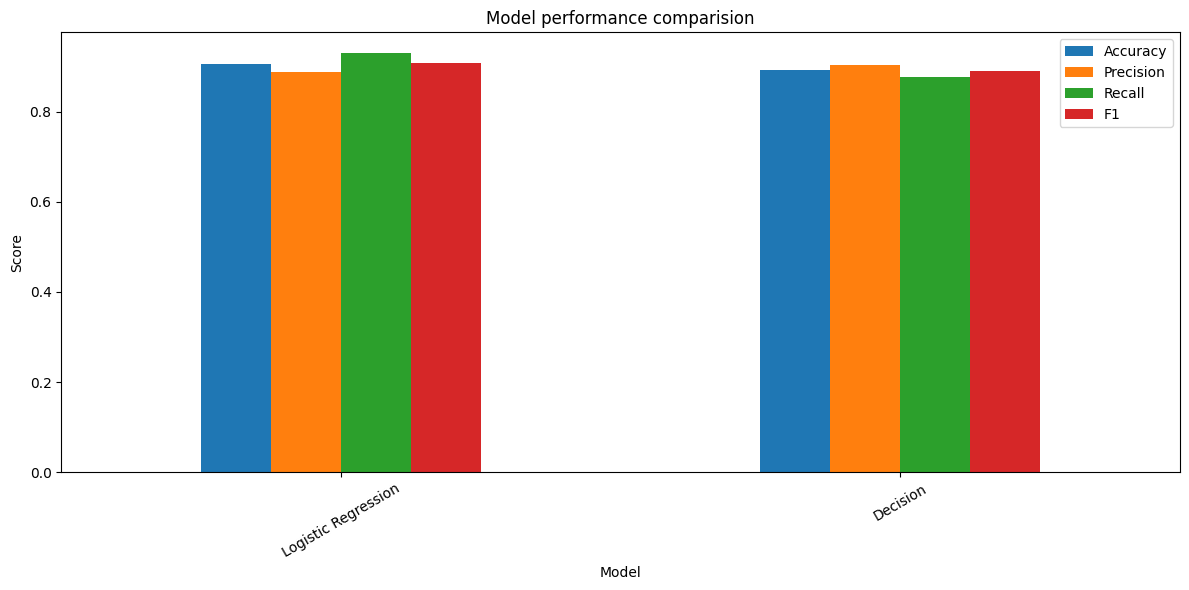

                 Model  Accuracy  Precision  ...   ROC-AUC    PR-AUC  Training time
2        Random Forest  0.936667   0.927869  ...  0.936699  0.904884       1.627470
0  Logistic Regression  0.906667   0.888179  ...  0.906743  0.860798       0.111576
1             Decision  0.891667   0.903448  ...  0.891615  0.853317       0.034375

[3 rows x 8 columns]


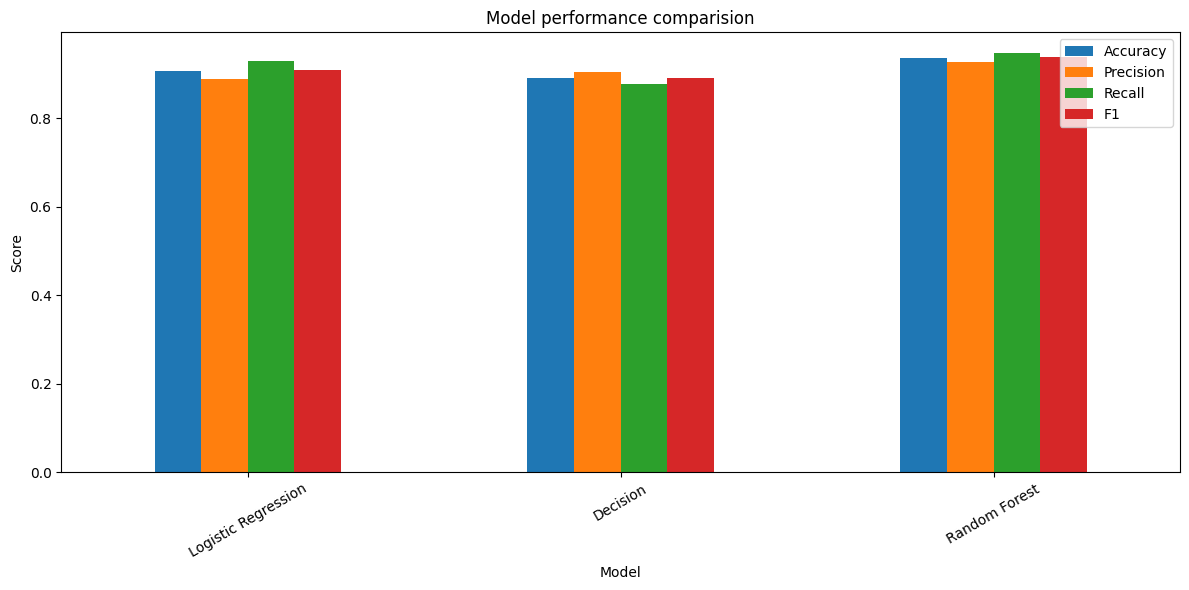

                 Model  Accuracy  Precision  ...   ROC-AUC    PR-AUC  Training time
3    Gradient Boosting  0.941667   0.942953  ...  0.941660  0.916187       1.270331
2        Random Forest  0.936667   0.927869  ...  0.936699  0.904884       1.627470
0  Logistic Regression  0.906667   0.888179  ...  0.906743  0.860798       0.111576
1             Decision  0.891667   0.903448  ...  0.891615  0.853317       0.034375

[4 rows x 8 columns]


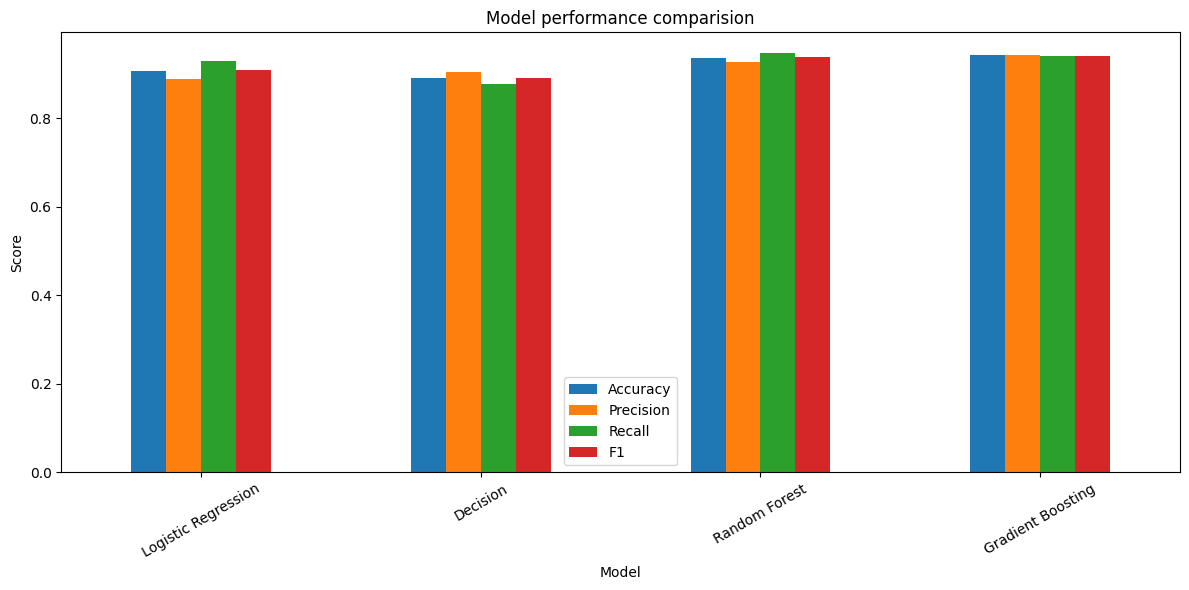

                 Model  Accuracy  Precision  ...   ROC-AUC    PR-AUC  Training time
4              XGBoost  0.943333   0.937294  ...  0.943355  0.915272       0.537748
3    Gradient Boosting  0.941667   0.942953  ...  0.941660  0.916187       1.270331
2        Random Forest  0.936667   0.927869  ...  0.936699  0.904884       1.627470
0  Logistic Regression  0.906667   0.888179  ...  0.906743  0.860798       0.111576
1             Decision  0.891667   0.903448  ...  0.891615  0.853317       0.034375

[5 rows x 8 columns]


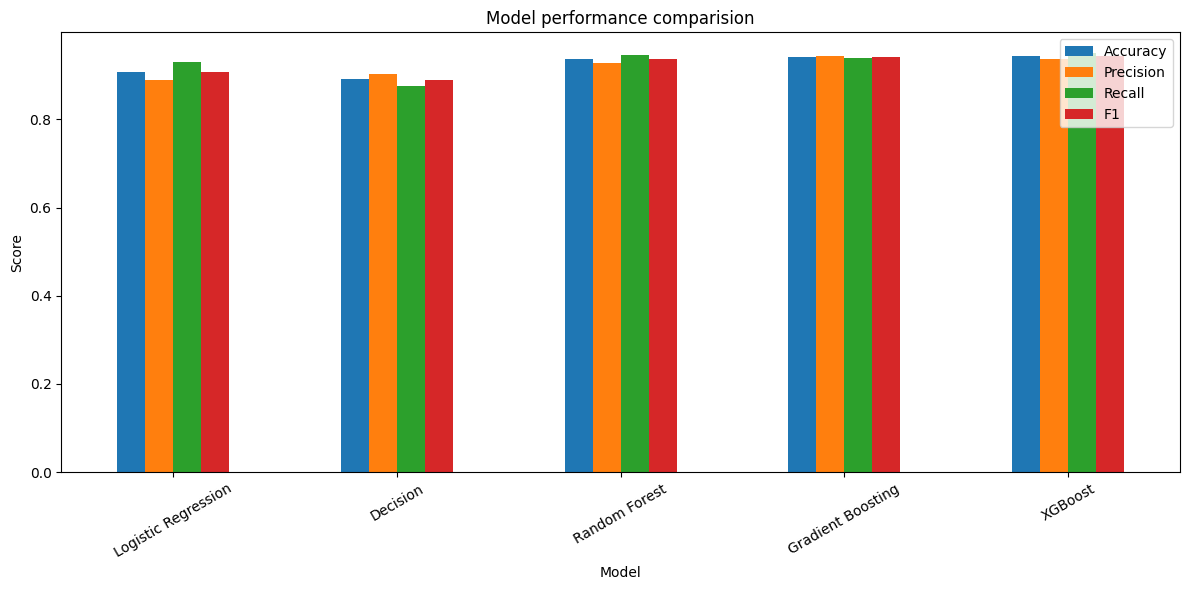

                 Model  Accuracy  Precision  ...   ROC-AUC    PR-AUC  Training time
5             LightGBM  0.946667   0.937705  ...  0.946699  0.918602       6.140080
4              XGBoost  0.943333   0.937294  ...  0.943355  0.915272       0.537748
3    Gradient Boosting  0.941667   0.942953  ...  0.941660  0.916187       1.270331
2        Random Forest  0.936667   0.927869  ...  0.936699  0.904884       1.627470
0  Logistic Regression  0.906667   0.888179  ...  0.906743  0.860798       0.111576
1             Decision  0.891667   0.903448  ...  0.891615  0.853317       0.034375

[6 rows x 8 columns]


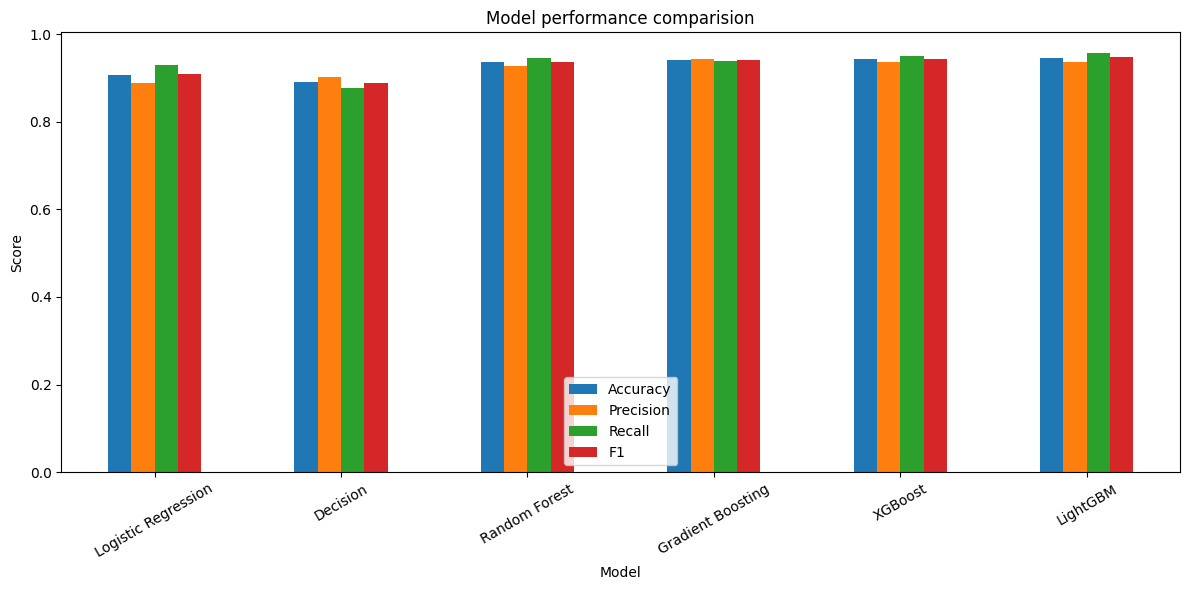

In [2]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
import pandas as pd
import time
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score
X, y = make_classification(
    n_samples=3000,
    n_features=10,
    n_informative=6,
    n_redundant=2,
    random_state=42
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

models={
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision":DecisionTreeClassifier(random_state=42),
    "Random Forest":RandomForestClassifier(n_estimators=200, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "XGBoost": XGBClassifier(n_estimators=200, learning_rate=0.05, eval_metrics="logloss", random_state=42),
    "LightGBM": LGBMClassifier(n_estimators=200, learning_rate=0.05, verbosity=-1, random_state=42)
}
results=[]
for name, model in models.items():
    start_time=time.time()
    model.fit(X_train, y_train)
    pred= model.predict(X_test)
    prob=model.predict_proba(X_test)[:,1]
    training_time= time.time()-start_time
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test,pred),
        "Precision": precision_score(y_test,pred),
        "Recall": recall_score(y_test,pred),
        "F1": f1_score(y_test,pred),
        "ROC-AUC": roc_auc_score(y_test,pred),
        "PR-AUC": average_precision_score(y_test,pred),
        "Training time": training_time
    })
    results_df=pd.DataFrame(results)
    print(results_df.sort_values(by="F1", ascending=False))
    import matplotlib.pyplot as plt
    results_df.plot(x="Model", y=["Accuracy", "Precision", "Recall", "F1"], kind="bar", figsize=(12, 6))
    plt.title("Model performance comparision")
    plt.ylabel("Score")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()